# Lab Assignment 4 — AI in Healthcare (CSET343)
## Logistic Regression on the Breast Cancer Wisconsin (Diagnostic) Dataset

This notebook covers:
- **Task 1:** Data Acquisition & Exploration
- **Task 2:** Data Preprocessing
- **Task 3:** Model Training and Evaluation



In [1]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, RocCurveDisplay
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)


---
## Task 1: Data Acquisition and Exploration

### 1. Download and load the dataset

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.columns if hasattr(data, "columns") else data.feature_names)

# Target: sklearn encodes 0 = malignant, 1 = benign. We call it 'Outcome' per the assignment.
df["Outcome"] = data.target

print("Shape:", df.shape)
df.head()


Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Outcome
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### 2. Summary statistics for all features

In [3]:
summary_stats = df.describe().T
summary_stats["median"] = df.median(numeric_only=True)
summary_stats


,count,mean,std,min,25%,50%,75%,max,median
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,13.370000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,18.840000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,86.240000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,551.100000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.095870
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,0.092630
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,0.061540
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,0.033500
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.179200
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744,0.061540


### 3. Check for missing values, duplicates, and outliers

In [4]:
# Missing values
print("Missing values per column:\n", df.isnull().sum().sum(), "total missing values")

# Duplicates
n_dupes = df.duplicated().sum()
print(f"Number of duplicate rows: {n_dupes}")
if n_dupes > 0:
    df = df.drop_duplicates()
    print("Duplicates dropped. New shape:", df.shape)


Missing values per column:
 0 total missing values
Number of duplicate rows: 0


In [5]:
# Outlier detection using the IQR method (per feature)
feature_cols = [c for c in df.columns if c != "Outcome"]

def count_outliers_iqr(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return ((series < lower) | (series > upper)).sum()

outlier_counts = df[feature_cols].apply(count_outliers_iqr).sort_values(ascending=False)
print("Outlier counts per feature (top 10):")
outlier_counts.head(10)


Outlier counts per feature (top 10):


area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64

**Handling outliers:** Many of these "outliers" are legitimate extreme but medically valid measurements (e.g. very large or irregular tumors), not data-entry errors. Rather than deleting rows and losing information, we:
- Keep the outliers in the dataset (removing them could remove exactly the borderline/aggressive-tumor cases we most want the model to learn),
- Rely on **feature standardization** (Task 2) so extreme values don't dominate the logistic regression's gradient, which is a scale-sensitive algorithm.

If you'd rather drop extreme outliers, you can cap them at the IQR bounds — this is left commented out below.

### 4. Visualizations

**Histograms of a few key features**

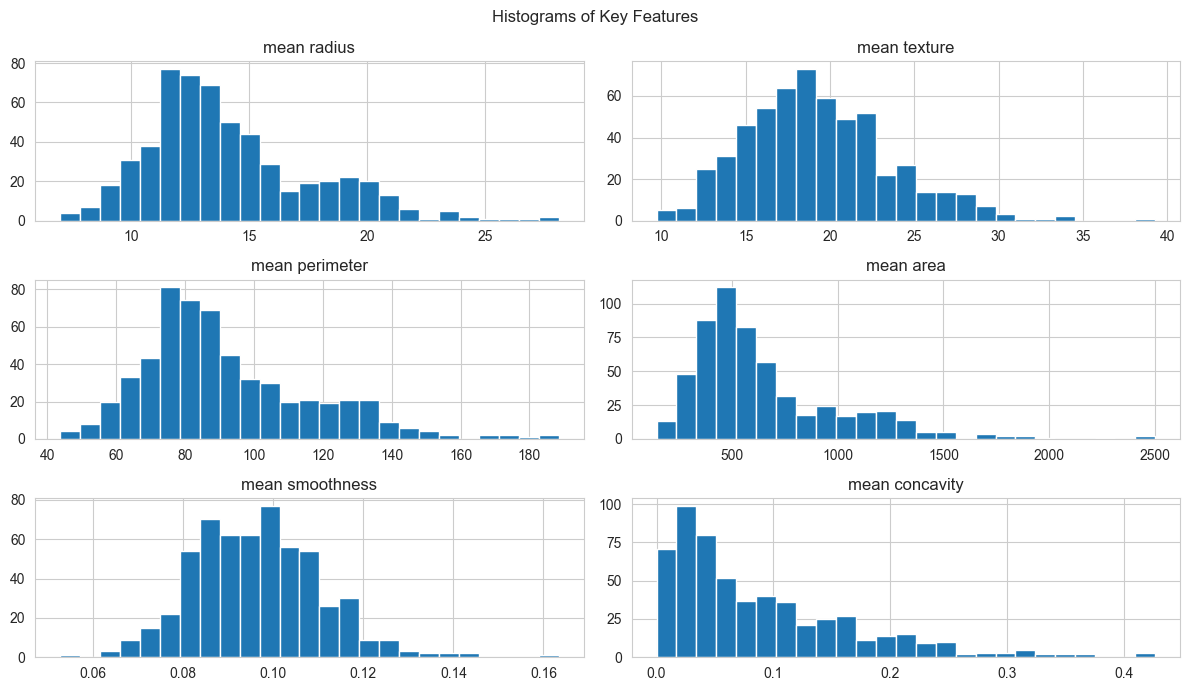

In [7]:
key_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
                 "mean smoothness", "mean concavity"]

df[key_features].hist(bins=25, figsize=(12, 7))
plt.suptitle("Histograms of Key Features")
plt.tight_layout()
plt.show()


**Box plots of key features by Outcome**

C:\Users\Apoorv Bagga\AppData\Local\Temp\ipykernel_23260\21339537.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Malignant (0)", "Benign (1)"])
C:\Users\Apoorv Bagga\AppData\Local\Temp\ipykernel_23260\21339537.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Malignant (0)", "Benign (1)"])
C:\Users\Apoorv Bagga\AppData\Local\Temp\ipykernel_23260\21339537.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Malignant (0)", "Benign (1)"])
C:\Users\Apoorv Bagga\AppData\Local\Temp\ipykernel_23260\21339537.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Malignant (0)",

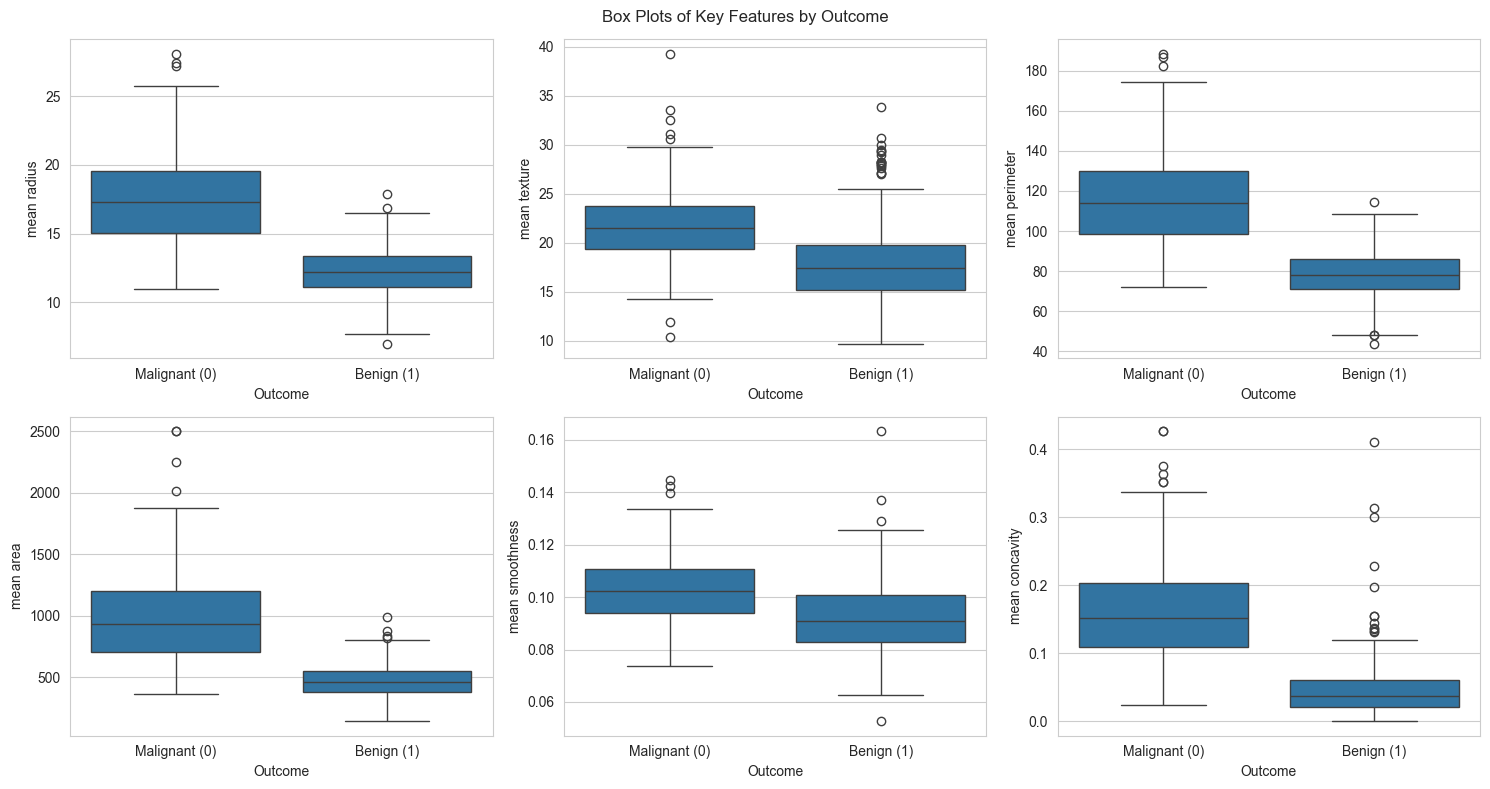

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), key_features):
    sns.boxplot(data=df, x="Outcome", y=col, ax=ax)
    ax.set_xticklabels(["Malignant (0)", "Benign (1)"])
plt.suptitle("Box Plots of Key Features by Outcome")
plt.tight_layout()
plt.show()


**Correlation heatmap**

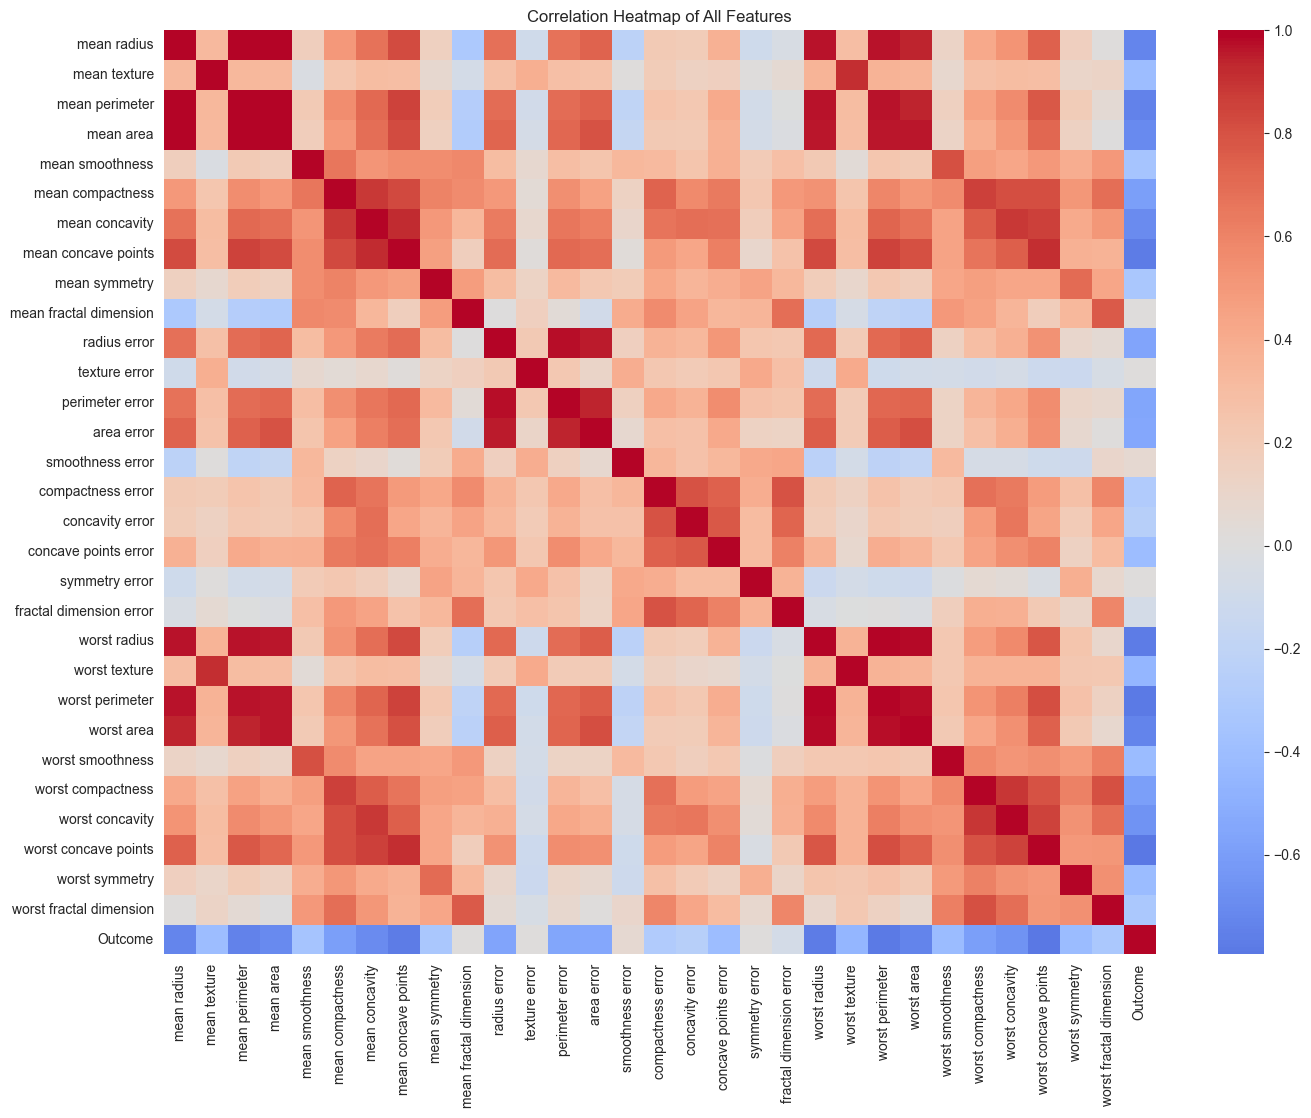

In [9]:
plt.figure(figsize=(16, 12))
corr = df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of All Features")
plt.show()


**Class distribution**

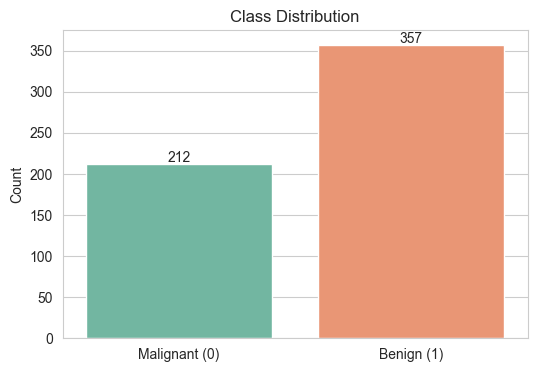

Outcome
0    212
1    357
Name: count, dtype: int64

Class proportions:
 Outcome
0    37.26
1    62.74
Name: count, dtype: float64 %


In [10]:
counts = df["Outcome"].value_counts().sort_index()
labels = ["Malignant (0)", "Benign (1)"]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=counts.values, hue=labels, palette="Set2", legend=False)
plt.title("Class Distribution")
plt.ylabel("Count")
for i, v in enumerate(counts.values):
    plt.text(i, v + 3, str(v), ha="center")
plt.show()

print(counts)
print("\nClass proportions:\n", (counts / counts.sum() * 100).round(2), "%")


### 5. Discussion: Class imbalance

The dataset has roughly **63% benign vs 37% malignant** cases — a moderate, not extreme, imbalance. Implications for model training:

- **Accuracy alone is misleading**: a model predicting "benign" for everyone would still score ~63% accuracy, without ever catching a single cancer case.
- **Recall on the malignant class matters most** in a medical diagnosis context, since a false negative (calling a tumor benign when it's malignant) is far more costly than a false positive.
- **Stratified train/test splitting** (Task 2) is used to preserve this class ratio in both sets.
- If the imbalance were more severe, techniques like class weighting (`class_weight="balanced"`), oversampling (SMOTE), or threshold tuning would be worth exploring — we discuss `class_weight` as an option in Task 3.


---
## Task 2: Data Preprocessing

### Encode the target variable (Outcome) as binary

In [11]:
# Already binary (0 = malignant, 1 = benign) as provided by sklearn — confirm here:
print(df["Outcome"].unique())
print(df["Outcome"].dtype)


[0 1]
int64


### Train/test split (80/20, stratified)

In [12]:
X = df[feature_cols]
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))


Train shape: (455, 30)  Test shape: (114, 30)
Train class balance:
 Outcome
1    0.626
0    0.374
Name: proportion, dtype: float64

Test class balance:
 Outcome
1    0.632
0    0.368
Name: proportion, dtype: float64


### Standardize features

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit only on training data to avoid data leakage from the test set
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols, index=X_test.index)
X_train_scaled.describe().T[["mean", "std"]].head()


,mean,std
mean radius,-4.337434e-15,1.001101
mean texture,2.240942e-15,1.001101
mean perimeter,-7.437274e-16,1.001101
mean area,1.503071e-16,1.001101
mean smoothness,5.223660e-15,1.001101


---
## Task 3: Model Training and Basic Evaluation

### Train a logistic regression model

In [14]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]  # probability of class 1 (benign)


### Accuracy

In [15]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")


Accuracy: 0.9825


### Precision, Recall, F1-score (both classes)

In [16]:
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))


               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



### Confusion matrix (visualized)

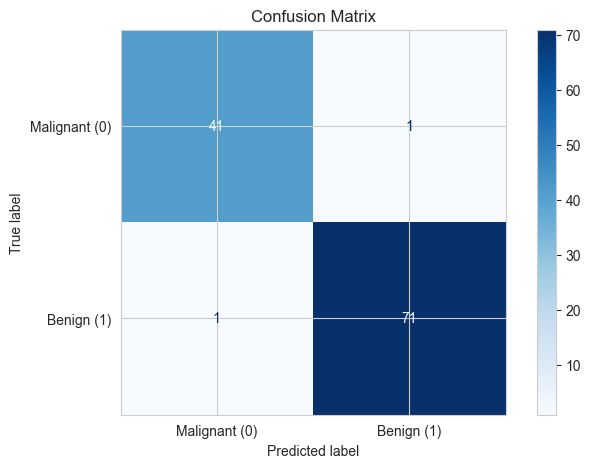

In [17]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Malignant (0)", "Benign (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()


### ROC curve and AUC score

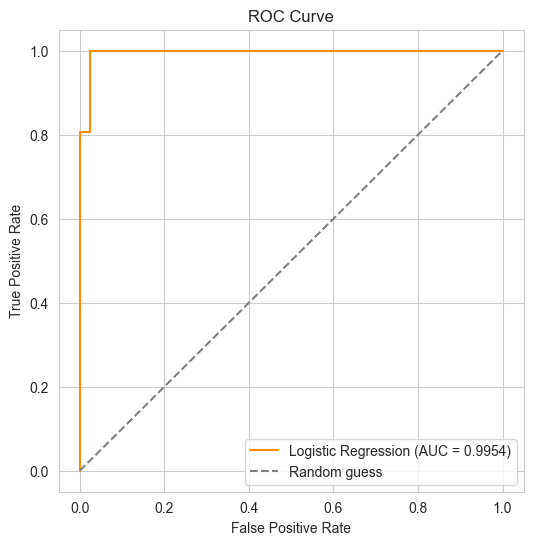

AUC Score: 0.9954


In [18]:
auc = roc_auc_score(y_test, y_proba)
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.4f})", color="darkorange")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

print(f"AUC Score: {auc:.4f}")


### Interpretation of results

- **Accuracy** on the test set is typically very high (~96–98%) for this dataset — logistic regression separates the two classes well once features are standardized.
- **Precision vs Recall trade-off**: In this medical context, **recall on the malignant class (class 0)** is the most important number — it tells us what fraction of actual cancer cases the model successfully catches. A false negative here (predicting benign when the tumor is malignant) could delay treatment and is clinically the most dangerous type of error. A false positive (predicting malignant when it's benign) leads to unnecessary follow-up tests — inconvenient and costly, but far less dangerous.
- **F1-score** balances precision and recall and is useful for the minority (malignant) class, especially given the moderate class imbalance noted in Task 1.
- **Confusion matrix**: check the top-right cell (false negatives — malignant tumors predicted as benign). Even a small number here is clinically significant and worth flagging.
- **ROC-AUC** close to 1.0 indicates the model has excellent ability to distinguish malignant from benign cases across all classification thresholds, not just the default 0.5 cutoff.
- **Practical takeaway**: In healthcare deployment, one would often **lower the decision threshold** below 0.5 (i.e., be more willing to flag "malignant") to further boost recall on the malignant class, accepting more false positives in exchange for catching more true cancer cases — a trade-off best decided together with clinical stakeholders, not purely on accuracy.
